# College Football Upset Vulnerability — Stage 1: Data Preparation


## 0. Setup and source file



In [ ]:
%pip install kagglehub

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import kagglehub

# Dataset configuration
DATASET = "cviaxmiwnptr/college-football-team-stats-2002-to-january-2024"
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
MIN_SEASON = 2004  # Provisional; verify during EDA

# Download the Kaggle dataset
dataset_path = Path(kagglehub.dataset_download(
    DATASET,
    output_dir=str(RAW_DIR)
))

# Locate the box-score CSV
csv_files = list(dataset_path.rglob("*.csv"))

print("Available CSV files:")
for file in csv_files:
    print(" -", file.name)

matches = [f for f in csv_files if "box-score" in f.name.lower()]

if len(matches) != 1:
    raise ValueError(
        f"Expected one box-score CSV, found {len(matches)}. "
        "Check the downloaded filenames."
    )

RAW_CSV = matches[0]

# Load the dataset
raw = pd.read_csv(RAW_CSV, low_memory=False)

# Display dataset information
print("\nPython:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("KaggleHub:", kagglehub.__version__)
print("Dataset file:", RAW_CSV)
print(f"Dataset shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

display(raw.head(10))

100%|██████████| 1.17M/1.17M [00:01<00:00, 1.20MB/s]

Extracting files...
Available CSV files:
 - cfb_box-scores_2002-2025.csv

Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
KaggleHub: 1.0.3
Dataset file: data/raw/cfb_box-scores_2002-2025.csv
Dataset shape: 19,843 rows x 58 columns


,season,week,date,time_et,game_type,away,home,rank_away,rank_home,conf_away,...,int_away,int_home,pen_num_away,pen_yards_away,pen_num_home,pen_yards_home,possession_away,possession_home,attendance,tv
0,2002,1.0,2002-08-22,7:30 PM,regular,Colorado State,Virginia,NaN,NaN,mwc,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57120.0,NaN
1,2002,1.0,2002-08-23,8:00 PM,regular,Fresno State,Wisconsin,NaN,25.0,wac,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75136.0,NaN
2,2002,1.0,2002-08-24,2:30 PM,regular,Texas Tech,Ohio State,NaN,13.0,big12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100037.0,NaN
3,2002,1.0,2002-08-24,4:30 PM,regular,New Mexico,NC State,NaN,NaN,mwc,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47018.0,NaN
4,2002,1.0,2002-08-24,7:45 PM,regular,Arizona State,Nebraska,NaN,10.0,pac12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77779.0,NaN
5,2002,1.0,2002-08-24,8:30 PM,regular,Florida State,Iowa State,3.0,NaN,acc,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55132.0,NaN
6,2002,1.0,2002-08-25,2:30 PM,regular,Arkansas State,Virginia Tech,NaN,16.0,sun-belt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54016.0,NaN
7,2002,2.0,2002-08-29,7:00 PM,regular,Cal Poly SLO,Toledo,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23074.0,NaN
8,2002,2.0,2002-08-29,7:00 PM,regular,New Hampshire,Kent State,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16073.0,NaN
9,2002,2.0,2002-08-29,7:00 PM,regular,Richmond,Temple,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15329.0,NaN


## 1. Examine schema and completeness


In [ ]:
display(pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
}).sort_values("missing_pct", ascending=False))
print("Columns:", list(raw.columns))
print("Season frequency (including missing):")
display(raw["season"].value_counts(dropna=False).sort_index())
print("Game types:")
display(raw["game_type"].value_counts(dropna=False))
print("Neutral-site values:")
display(raw["neutral"].value_counts(dropna=False))

,dtype,non_null,missing,missing_pct
rank_away,float64,3537,16306,82.18
rank_home,float64,4425,15418,77.70
tv,object,14830,5013,25.26
attendance,float64,15630,4213,21.23
conf_away,object,17576,2267,11.42
possession_away,float64,18231,1612,8.12
possession_home,float64,18257,1586,7.99
first_downs_away,float64,18261,1582,7.97
third_down_att_away,float64,18261,1582,7.97
third_down_comp_away,float64,18261,1582,7.97


Columns: ['season', 'week', 'date', 'time_et', 'game_type', 'away', 'home', 'rank_away', 'rank_home', 'conf_away', 'conf_home', 'neutral', 'score_away', 'score_home', 'q1_away', 'q2_away', 'q3_away', 'q4_away', 'ot_away', 'q1_home', 'q2_home', 'q3_home', 'q4_home', 'ot_home', 'first_downs_away', 'first_downs_home', 'third_down_comp_away', 'third_down_att_away', 'third_down_comp_home', 'third_down_att_home', 'fourth_down_comp_away', 'fourth_down_att_away', 'fourth_down_comp_home', 'fourth_down_att_home', 'pass_comp_away', 'pass_att_away', 'pass_yards_away', 'pass_comp_home', 'pass_att_home', 'pass_yards_home', 'rush_att_away', 'rush_yards_away', 'rush_att_home', 'rush_yards_home', 'total_yards_away', 'total_yards_home', 'fum_away', 'fum_home', 'int_away', 'int_home', 'pen_num_away', 'pen_yards_away', 'pen_num_home', 'pen_yards_home', 'possession_away', 'possession_home', 'attendance', 'tv']
Season frequency (including missing):


,count
season,
2002,772
2003,771
2004,707
2005,718
2006,791
2007,792
2008,804
2009,808
2010,808


Game types:


,count
game_type,
regular,18978
post,865


Neutral-site values:


,count
neutral,
False,18818
True,1025


### Box-score coverage by season



In [ ]:
box_cols = [c for c in [
    "total_yards_home", "total_yards_away", "pass_yards_home", "pass_yards_away",
    "rush_yards_home", "rush_yards_away", "fum_home", "fum_away", "int_home", "int_away"
] if c in raw.columns]

coverage = raw.groupby("season", dropna=False)[box_cols].agg(
    lambda x: round(x.notna().mean() * 100, 1)
)
display(coverage)
print("Coverage represents percentage of rows with a non-missing statistic, by season.")

,total_yards_home,total_yards_away,pass_yards_home,pass_yards_away,rush_yards_home,rush_yards_away,fum_home,fum_away,int_home,int_away
season,,,,,,,,,,
2002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2004,98.9,98.9,98.9,98.9,98.9,98.9,98.9,98.9,98.9,98.9
2005,98.6,98.6,98.6,98.6,98.6,98.6,98.6,98.6,98.6,98.6
2006,99.9,99.9,99.9,99.9,99.9,99.9,99.9,99.9,99.9,99.9
2007,99.4,99.4,99.4,99.4,99.4,99.4,99.4,99.4,99.4,99.4
2008,99.9,99.8,99.9,99.8,99.9,99.8,99.9,99.8,99.9,99.8
2009,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2010,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


Coverage represents percentage of rows with a non-missing statistic, by season.


## 2. Data quality checks



In [ ]:
games = raw.copy()
games.columns = games.columns.str.strip()

numeric_fields = ["season", "week", "score_home", "score_away"]
for col in numeric_fields:
    games[col] = pd.to_numeric(games[col], errors="coerce")
games["date"] = pd.to_datetime(games["date"], errors="coerce")
for col in ["home", "away"]:
    games[col] = games[col].astype("string").str.strip()

invalid_dates = games[games["date"].isna()]
missing_teams = games[games[["home", "away"]].isna().any(axis=1)]
missing_scores = games[games[["score_home", "score_away"]].isna().any(axis=1)]
negative_scores = games[(games[["score_home", "score_away"]] < 0).any(axis=1)]
valid_score_mask = games[["score_home", "score_away"]].notna().all(axis=1)
ties = games[valid_score_mask & games["score_home"].eq(games["score_away"])]

print("Invalid dates:", len(invalid_dates))
print("Missing home/away team:", len(missing_teams))
print("Missing scores (possible unplayed games):", len(missing_scores))
print("Negative scores:", len(negative_scores))
print("Tied final scores:", len(ties))

# A repeated same-day pairing is a candidate duplicate, not necessarily proof of one.
dup_key = ["season", "date", "away", "home", "game_type"]
duplicate_candidates = games[games.duplicated(dup_key, keep=False)].sort_values(dup_key)
print("Possible duplicate records:", len(duplicate_candidates))
display(duplicate_candidates[dup_key + ["score_away", "score_home"]].head(25))
if len(ties):
    display(ties[dup_key + ["score_away", "score_home"]].head(25))

Invalid dates: 0
Missing home/away team: 0
Missing scores (possible unplayed games): 0
Negative scores: 0
Tied final scores: 0
Possible duplicate records: 0


,season,date,away,home,game_type,score_away,score_home


## 3. Define the clean game-level analysis table



In [ ]:
# Stop on ambiguous quality issues rather than quietly deleting examples.
if len(negative_scores) or len(ties) or len(duplicate_candidates):
    raise ValueError(
        "Review the negative-score, tie, or duplicate candidate records above before "
        "exporting a clean dataset. Document any exceptions or corrections."
    )

eligible = (
    games["season"].ge(MIN_SEASON)
    & games["date"].notna()
    & games[["home", "away"]].notna().all(axis=1)
    & valid_score_mask
    & games["score_home"].ge(0)
    & games["score_away"].ge(0)
)
clean = games.loc[eligible].copy()
clean = clean.sort_values(["date", "time_et", "home", "away"], kind="stable").reset_index(drop=True)
clean.insert(0, "game_id", np.arange(1, len(clean) + 1, dtype=int))
clean["home_win"] = clean["score_home"].gt(clean["score_away"]).astype(int)
clean["home_margin"] = clean["score_home"] - clean["score_away"]

print(f"Raw games: {len(games):,}")
print(f"Eligible games: {len(clean):,}")
print(f"Excluded: {len(games) - len(clean):,}")
print(f"Season range: {clean.season.min():.0f}–{clean.season.max():.0f}")
assert not clean["game_id"].duplicated().any()
assert clean[["date", "home", "away", "score_home", "score_away"]].notna().all().all()
assert clean["home_margin"].ne(0).all()
display(clean[["game_id", "season", "date", "away", "home", "score_away", "score_home", "home_win", "home_margin"]].tail(10))

Raw games: 19,843
Eligible games: 18,300
Excluded: 1,543
Season range: 2004–2025


,game_id,season,date,away,home,score_away,score_home,home_win,home_margin
18290,18291,2025,2026-01-01,Oregon,Texas Tech,23,0,0,-23
18291,18292,2025,2026-01-01,Alabama,Indiana,3,38,1,35
18292,18293,2025,2026-01-01,Ole Miss,Georgia,39,34,0,-5
18293,18294,2025,2026-01-02,Rice,Texas State,10,41,1,31
18294,18295,2025,2026-01-02,Navy,Cincinnati,35,13,0,-22
18295,18296,2025,2026-01-02,Wake Forest,Mississippi State,43,29,0,-14
18296,18297,2025,2026-01-02,Arizona,SMU,19,24,1,5
18297,18298,2025,2026-01-08,Miami (FL),Ole Miss,31,27,0,-4
18298,18299,2025,2026-01-09,Oregon,Indiana,22,56,1,34
18299,18300,2025,2026-01-19,Miami (FL),Indiana,21,27,1,6


## 4. Basic exploratory data analysis


,n_games,home_win_rate,mean_home_margin
season,,,
2004,707,0.650636,8.376238
2005,718,0.596100,6.357939
2006,791,0.623262,6.874842
2007,792,0.622475,7.286616
2008,804,0.628109,7.342040
2009,808,0.636139,7.211634
2010,808,0.605198,6.508663
2011,812,0.637931,7.869458
2012,840,0.613095,7.930952


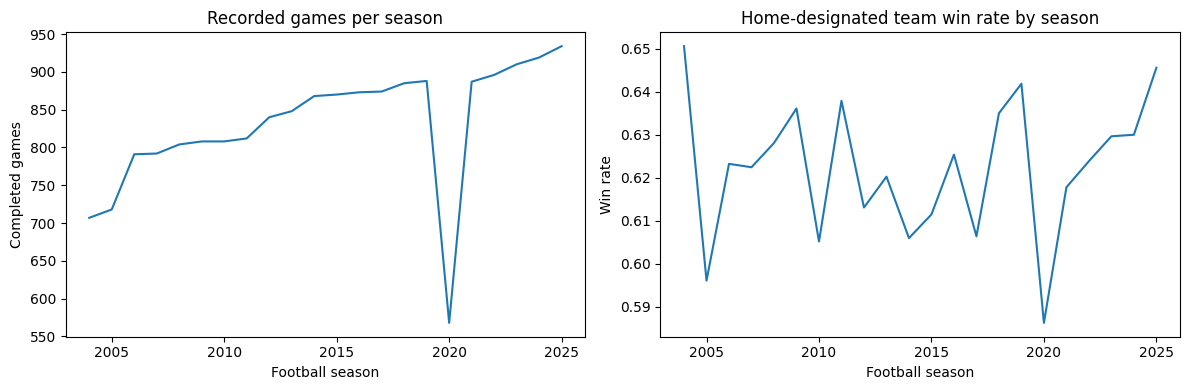

Important: 'home' includes designated home teams at neutral-site games.


In [ ]:
import matplotlib.pyplot as plt

season_summary = clean.groupby("season").agg(
    n_games=("game_id", "count"),
    home_win_rate=("home_win", "mean"),
    mean_home_margin=("home_margin", "mean"),
)
display(season_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
season_summary["n_games"].plot(ax=axes[0], title="Recorded games per season")
axes[0].set(xlabel="Football season", ylabel="Completed games")
season_summary["home_win_rate"].plot(ax=axes[1], title="Home-designated team win rate by season")
axes[1].set(xlabel="Football season", ylabel="Win rate")
plt.tight_layout()
plt.show()

print("Important: 'home' includes designated home teams at neutral-site games.")

Number of unique team labels: 249
Neutral-site label distribution:


,count
neutral,
False,17278
True,1022


Outcome balance:


,proportion
home_win,
1,0.62306
0,0.37694


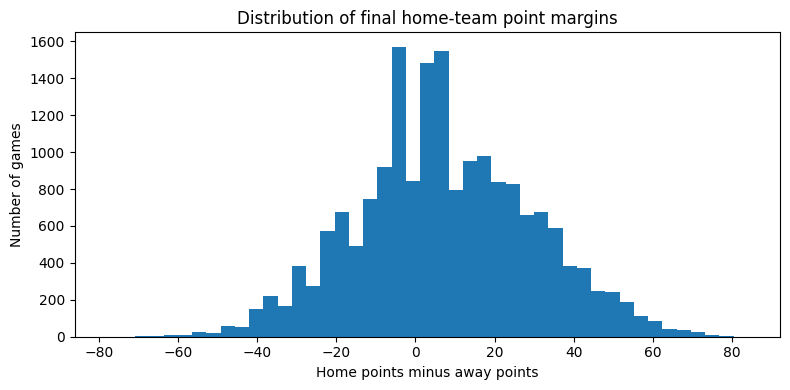

In [ ]:
print("Number of unique team labels:", pd.unique(pd.concat([clean["home"], clean["away"]])).size)
print("Neutral-site label distribution:")
display(clean["neutral"].value_counts(dropna=False))
print("Outcome balance:")
display(clean["home_win"].value_counts(normalize=True).rename("proportion"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(clean["home_margin"], bins=45)
ax.set(title="Distribution of final home-team point margins", xlabel="Home points minus away points", ylabel="Number of games")
plt.tight_layout()
plt.show()

## 5. Export and record decisions



In [ ]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
output_path = PROCESSED_DIR / "games_clean.csv"
clean.to_csv(output_path, index=False)
print("Saved:", output_path.resolve())
print("Rows:", len(clean), "Columns:", len(clean.columns))

Saved: /content/data/processed/games_clean.csv
Rows: 18300 Columns: 61


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Persistent project directory
PROJECT_DIR = Path("/content/drive/MyDrive/CFB_Upset_Project")

# Create project folders
for folder in [
    "notebooks",
    "data/raw",
    "data/processed",
    "outputs"
]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Save original and cleaned datasets permanently
files_to_save = [
    (Path("data/raw/cfb_box-scores_2002-2025.csv"),
     PROJECT_DIR / "data/raw"),
    (Path("data/processed/games_clean.csv"),
     PROJECT_DIR / "data/processed")
]

for source, destination in files_to_save:
    if not source.is_file():
        raise FileNotFoundError(f"Missing file: {source}")
    shutil.copy2(source, destination / source.name)
    print(f"Saved: {destination / source.name}")


Mounted at /content/drive
Saved: /content/drive/MyDrive/CFB_Upset_Project/data/raw/cfb_box-scores_2002-2025.csv
Saved: /content/drive/MyDrive/CFB_Upset_Project/data/processed/games_clean.csv
